## Generating the datasets' metadata and actual relations

The cell below generates `total_datasets_to_be_generated` datasets. No input data is generated yet. For each dataset, it randomly picks:

- **dimension**: the number of features (1 to 9)
- **samples size**: the number of samples (100 to 4999)
- **noise intensity**: a value between 0 (low noise) and 1 (high noise), not applied yet
- **relation**: `linear` or `non-linear`, using the probabilities in `relation_probabilities`

Then it builds the **actual relation**, the function the regressor will later try to estimate:

- **linear**: $y = w_0 + w_1 x_1 + \dots + w_d x_d$
- **non-linear** (the generalized linear form from the lecture): $y = w_0 + w_1 \phi_1(x_1) + \dots + w_d \phi_d(x_d)$, where each feature gets its own function $\phi_j$, picked randomly from `non_linear_functions` (a polynomial of degree 2 to 10, sin, cos, log, sqrt, abs, tanh, sigmoid or gaussian)

The weights $w_0, \dots, w_d$ are picked randomly between -10 and 10. Each dataset is stored in `datasets` as a tuple:
`(dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula)`, where `formula` is a readable version of the relation. Finally, the cell prints every dataset's metadata.

In [4]:
import numpy as np
from numpy.random import PCG64

total_datasets_to_be_generated = 10

rng = np.random.Generator(PCG64())

relation_types = ("linear", "non-linear")
relation_probabilities = [0.8, 0.2]

non_linear_functions = {
    "polynomial": lambda x, degree: x ** degree,
    "sin": lambda x: np.sin(x),
    "cos": lambda x: np.cos(x),
    "log": lambda x: np.log(np.abs(x) + 1),
    "sqrt": lambda x: np.sqrt(np.abs(x)),
    "abs": lambda x: np.abs(x),
    "tanh": lambda x: np.tanh(x),
    "sigmoid": lambda x: 1 / (1 + np.exp(-x)),
    "gaussian": lambda x: np.exp(-x ** 2 / 2),
}

datasets = []

for _ in range(total_datasets_to_be_generated):
    dimension = int(9 * rng.random(size=None) + 1)

    samples_size = int(4900 * rng.random(size=None) + 100)

    noise_intensity = rng.random(size=None)

    relation = rng.choice(relation_types, p=relation_probabilities)

    actual_relation = None

    if relation == "linear":
        weights = rng.uniform(-10, 10, size=dimension + 1)
        actual_relation = lambda X, weights=weights: weights[0] + X @ weights[1:]
        formula = f"y = {weights[0]:.2f}"
        for j in range(dimension):
            formula += f" + ({weights[j + 1]:.2f})·x{j + 1}"
    else:
        weights = rng.uniform(-10, 10, size=dimension + 1)
        feature_functions = []
        formula = f"y = {weights[0]:.2f}"
        for j in range(dimension):
            name = rng.choice(list(non_linear_functions))
            if name == "polynomial":
                degree = int(rng.integers(2, 11))
                feature_functions.append(lambda x, degree=degree: non_linear_functions["polynomial"](x, degree))
                formula += f" + ({weights[j + 1]:.2f})·x{j + 1}^{degree}"
            else:
                feature_functions.append(non_linear_functions[name])
                formula += f" + ({weights[j + 1]:.2f})·{name}(x{j + 1})"
        actual_relation = lambda X, weights=weights, feature_functions=feature_functions, dimension=dimension: weights[0] + sum(weights[j + 1] * feature_functions[j](X[:, j]) for j in range(dimension))

    datasets.append((dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula))

for i, (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula) in enumerate(datasets):
    print(f"dataset {i + 1}:")
    print(f"  dimension:       {dimension}")
    print(f"  samples size:    {samples_size}")
    print(f"  noise intensity: {noise_intensity:.2f}")
    print(f"  relation:        {relation}")
    print(f"  weights:         {weights}")
    print(f"  formula:         {formula}")

dataset 1:
  dimension:    1
  samples size: 4748
  noise:        0.63
  relation:     linear
  weights:      [ 8.7531644  -0.10730634]
  formula:      y = 8.75 + (-0.11)·x1
dataset 2:
  dimension:    1
  samples size: 2368
  noise:        0.16
  relation:     linear
  weights:      [6.41880368 6.90881034]
  formula:      y = 6.42 + (6.91)·x1
dataset 3:
  dimension:    4
  samples size: 2953
  noise:        0.11
  relation:     linear
  weights:      [ 6.32360161 -8.27931217  9.98886144 -6.27164003  7.61117308]
  formula:      y = 6.32 + (-8.28)·x1 + (9.99)·x2 + (-6.27)·x3 + (7.61)·x4
dataset 4:
  dimension:    7
  samples size: 3102
  noise:        0.11
  relation:     linear
  weights:      [-9.74413744 -9.74618822  6.49146812 -7.16163922  7.25373246 -4.01103399
  4.729886    6.37595243]
  formula:      y = -9.74 + (-9.75)·x1 + (6.49)·x2 + (-7.16)·x3 + (7.25)·x4 + (-4.01)·x5 + (4.73)·x6 + (6.38)·x7
dataset 5:
  dimension:    1
  samples size: 1334
  noise:        0.19
  relation:    

## Generating the sample data

The cell below uses each dataset's metadata to generate its samples:

- **inputs** `X`: a `samples_size × dimension` matrix, each value picked uniformly between -1000 and 1000
- **clean outputs** `y_clean`: the actual relation applied to the inputs, $f(\mathbf{x})$
- **noisy outputs** `y`: the clean outputs plus Gaussian noise, $y = f(\mathbf{x}) + \varepsilon$, where $\varepsilon \sim \mathcal{N}(0, \sigma^2)$

The noise's standard deviation is scaled to each dataset's outputs: $\sigma = \text{noise\_intensity} \times \text{std}(y_{clean})$. This way `noise_intensity` means the same in every dataset, whatever the size of its outputs: 0 means no noise, 0.5 means noise about half as large as the spread of the outputs, and 1 means noise as large as the spread itself.

### Why the noise is random and not a constant

Adding the same constant $c$ to every target value is not real noise. It only shifts the whole relation: $y = f(\mathbf{x}) + c$, which is the same as changing the bias from $w_0$ to $w_0 + c$. That is a new, perfectly regular pattern, so the regressor would learn it exactly and none of it would count as error. Real noise is different for each sample, unpredictable from the input, and averages out to zero. That's why a separate random value $\varepsilon$ is drawn for every sample.

The samples are stored in `samples` as `(X, y)` tuples, in the same order as `datasets`, so `samples[i]` belongs to `datasets[i]`. They are also added to each dataset's tuple as an 8th field, so every tuple in `datasets` becomes:
`(dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y))`.

Finally, the cell prints the first 15 patterns of each dataset and, for every 1-dimensional dataset, draws a scatter plot of its samples ($x_1$ against $y$).

dataset 1:
  x = [  -533.89]  ->  y = 78.70
  x = [   212.91]  ->  y = -85.74
  x = [  -319.79]  ->  y = 32.98
  x = [  -761.09]  ->  y = 27.73
  x = [  -848.65]  ->  y = 100.15
  x = [   454.19]  ->  y = -42.72
  x = [  -265.46]  ->  y = 4.62
  x = [    19.70]  ->  y = -97.23
  x = [   963.43]  ->  y = -62.17
  x = [  -651.41]  ->  y = 112.46
  x = [  -748.49]  ->  y = 114.84
  x = [   702.27]  ->  y = -58.86
  x = [   895.27]  ->  y = -160.09
  x = [   511.23]  ->  y = -112.31
  x = [  -624.01]  ->  y = 134.82
dataset 2:
  x = [   303.90]  ->  y = 3174.45
  x = [  -486.50]  ->  y = -2998.21
  x = [  -344.49]  ->  y = -3030.22
  x = [  -788.16]  ->  y = -5022.91
  x = [   317.66]  ->  y = 3636.76
  x = [   380.10]  ->  y = 3405.96
  x = [   639.88]  ->  y = 3411.99
  x = [   -78.79]  ->  y = -133.70
  x = [  -904.43]  ->  y = -5812.24
  x = [   352.75]  ->  y = 1566.31
  x = [  -241.58]  ->  y = -2930.31
  x = [  -440.30]  ->  y = -2633.61
  x = [   316.21]  ->  y = 2060.02
  x = [   

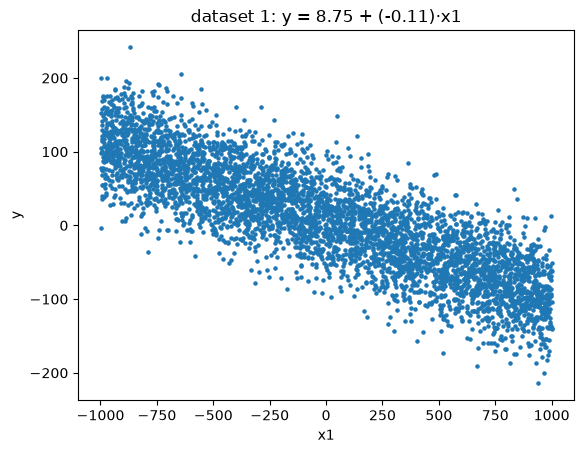

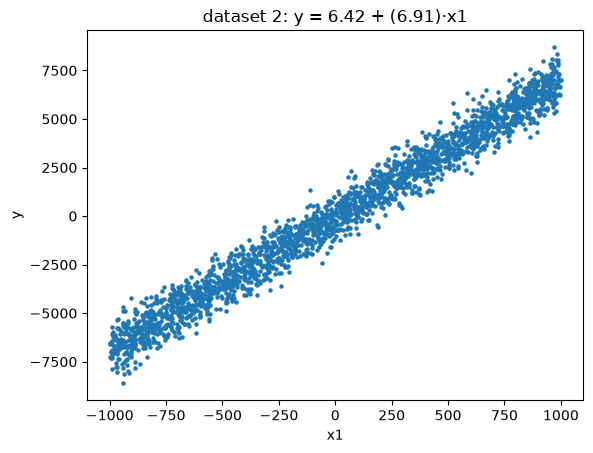

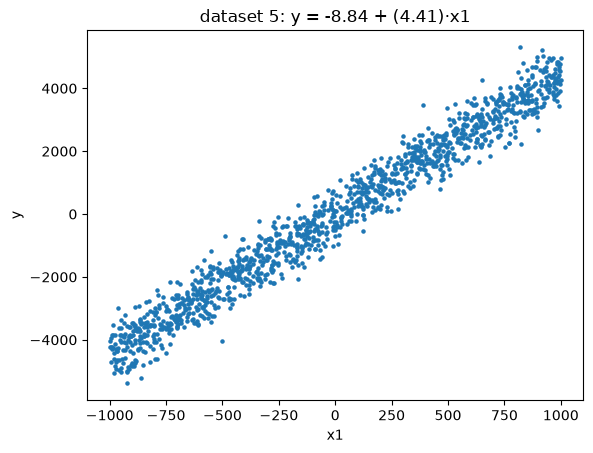

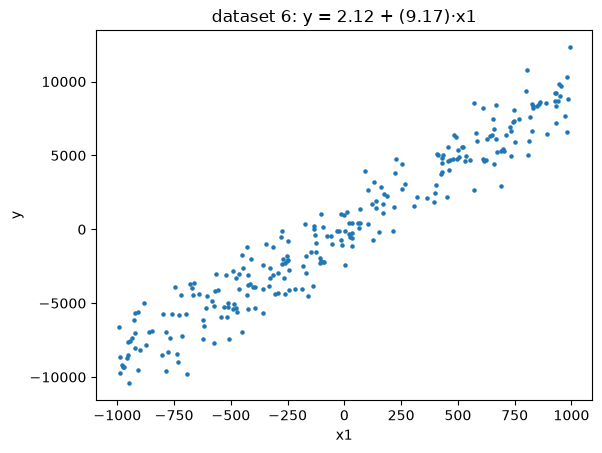

In [6]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["figure.dpi"] = 150

samples = []

for i in range(len(datasets)):
    dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula = datasets[i][:7]
    X = rng.uniform(-1000, 1000, size=(samples_size, dimension))
    y_clean = actual_relation(X)
    noise_std = noise_intensity * np.std(y_clean)
    y = y_clean + rng.normal(0, noise_std, size=samples_size)
    samples.append((X, y))
    datasets[i] = datasets[i][:7] + ((X, y),)

for i, (X, y) in enumerate(samples):
    print(f"dataset {i + 1}:")
    for k in range(15):
        features = ", ".join(f"{value:9.2f}" for value in X[k])
        print(f"  x = [{features}]  ->  y = {y[k]:.2f}")

one_dimensional_found = False

for i, (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y)) in enumerate(datasets):
    if dimension == 1:
        one_dimensional_found = True
        plt.figure()
        plt.scatter(X[:, 0], y, s=5)
        plt.title(f"dataset {i + 1}: {formula}")
        plt.xlabel("x1")
        plt.ylabel("y")
        plt.show()

if not one_dimensional_found:
    print("there are no 1-dimensional datasets to visualize")

## 10-fold cross validation and linear regression

The cell below finds a linear regressor for every dataset and measures its error with $k$-fold cross validation ($k = 10$):

1. A column of ones is added in front of `X` (`X_with_bias`) so the bias $w_0$ is learned as well.
2. The samples are divided into 10 folds. In each of the 10 iterations, one fold is the **test** data and the other 9 are the **training** data, so every sample is used for testing exactly once.
3. On the training data, the regressor is found with the least squares (normal equation) method from the lecture: $\mathbf{w} = (X^T X)^{-1} X^T \mathbf{y}$.
4. On the test data, the regressor's error is measured. Every test sample has the same weight $\frac{1}{n}$:
   - $RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (\hat{y}_i - y_i)^2}$
   - $MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$
   - $MAPE = \frac{1}{n}\sum_{i=1}^{n} \left|\frac{y_i - \hat{y}_i}{y_i}\right| \cdot 100\%$. It becomes very large when some targets are close to 0, because it divides by each $y_i$.
   - $R^2 = 1 - \frac{\sum_{i}(y_i - \hat{y}_i)^2}{\sum_{i}(y_i - \bar{y})^2}$, the coefficient of determination: 1 is a perfect fit, 0 is no better than always predicting the mean $\bar{y}$
5. Each error is averaged over the 10 folds: $E = \frac{1}{10}\sum_{i=1}^{10} E_i$.

The results are stored in `cross_validation_results`, in the same order as `datasets`. Each entry is `(fold_results, average_rmse, average_mae, average_mape, average_r2)`, where `fold_results` holds `(w, rmse, mae, mape, r2)` for each fold.

For every dataset, the cell prints each fold's errors with its estimated regressor, then the averages. For 1-dimensional datasets, it also plots the samples together with the 10 regression lines.

dataset 1: y = 8.75 + (-0.11)·x1
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1        38.3124        30.2519       243.0605     0.7152   y = 8.2741 + (-0.1074)·x1
       2        40.7023        32.4271       385.2208     0.7103   y = 8.4415 + (-0.1074)·x1
       3        38.7008        31.2370       167.0764     0.7465   y = 8.5234 + (-0.1073)·x1
       4        39.4540        31.2520       332.0986     0.7225   y = 8.2712 + (-0.1072)·x1
       5        39.3935        31.5270       327.2026     0.7022   y = 8.3466 + (-0.1083)·x1
       6        38.4339        30.6892       186.1038     0.7217   y = 8.3373 + (-0.1074)·x1
       7        36.5632        29.1214       343.3218     0.7512   y = 8.1207 + (-0.1073)·x1
       8        41.9212        33.6371       416.4650     0.7012   y = 8.4033 + (-0.1070)·x1
       9        38.6777        31.2254       291.7401     0.6792   y = 8.0119 + (-0.1082)·x1
      10        39.5928        31.6037     

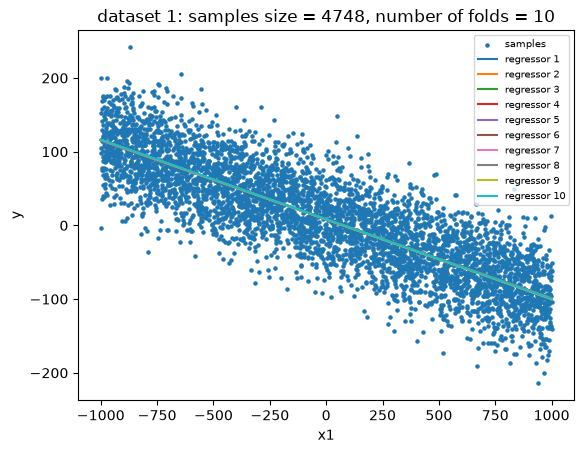


dataset 2: y = 6.42 + (6.91)·x1
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1       660.2357       520.2647        36.6002     0.9745   y = 6.2484 + (6.9256)·x1
       2       668.3832       535.0745        53.5766     0.9739   y = 13.5687 + (6.9313)·x1
       3       683.5164       545.7931        45.0570     0.9705   y = 11.5721 + (6.9340)·x1
       4       633.2468       499.1505        68.8190     0.9783   y = 13.5800 + (6.9236)·x1
       5       646.4882       507.7554        45.3879     0.9741   y = 9.6115 + (6.9266)·x1
       6       683.0564       554.5548        48.3238     0.9733   y = 16.4133 + (6.9323)·x1
       7       676.9767       538.1691        29.6271     0.9742   y = 12.5796 + (6.9324)·x1
       8       684.8962       556.6915        39.0028     0.9696   y = -1.6669 + (6.9452)·x1
       9       621.8768       493.8334        55.8517     0.9761   y = 14.1066 + (6.9284)·x1
      10       700.3288       553.7793       

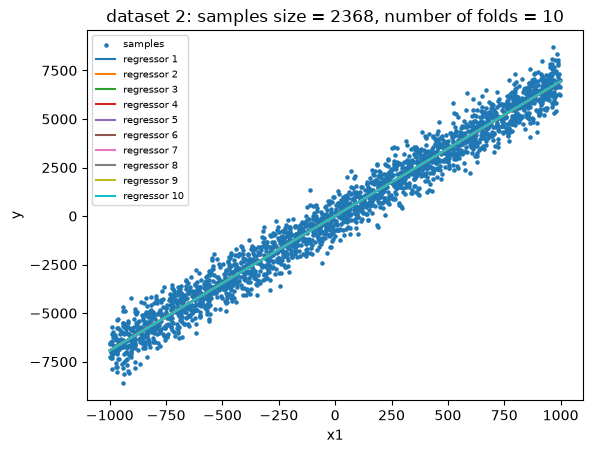


dataset 3: y = 6.32 + (-8.28)·x1 + (9.99)·x2 + (-6.27)·x3 + (7.61)·x4
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1      1050.6554       831.8483       657.9327     0.9885   y = 25.7581 + (-8.2225)·x1 + (10.0372)·x2 + (-6.2768)·x3 + (7.6684)·x4
       2      1049.9809       843.6312        42.7973     0.9870   y = 24.3025 + (-8.2403)·x1 + (10.0256)·x2 + (-6.2540)·x3 + (7.6231)·x4
       3      1057.6160       868.3865        58.7646     0.9863   y = 22.6465 + (-8.2371)·x1 + (10.0310)·x2 + (-6.2737)·x3 + (7.6304)·x4
       4      1116.7615       883.8796        67.4117     0.9838   y = 24.7475 + (-8.2219)·x1 + (10.0097)·x2 + (-6.2676)·x3 + (7.6164)·x4
       5      1042.8340       841.8399       137.8361     0.9887   y = 22.9341 + (-8.2131)·x1 + (10.0237)·x2 + (-6.2859)·x3 + (7.6482)·x4
       6      1071.2114       834.1825        40.3967     0.9854   y = 22.6387 + (-8.2313)·x1 + (10.0100)·x2 + (-6.2374)·x3 + (7.6505)·x4
       7      

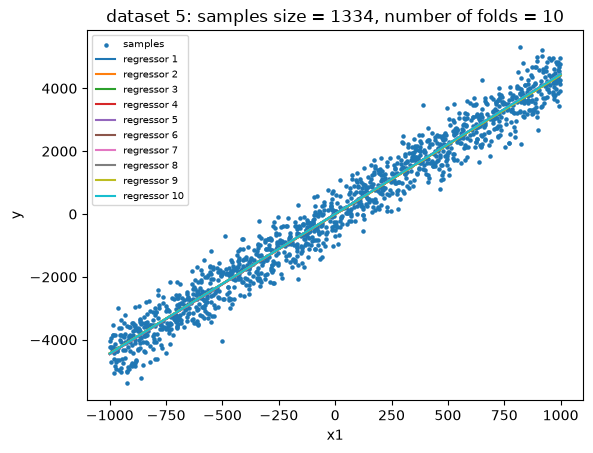


dataset 6: y = 2.12 + (9.17)·x1
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1      1426.7675      1184.2903        51.2070     0.9458   y = 119.8193 + (9.1020)·x1
       2      1250.6662       985.6661       122.9560     0.9424   y = 146.8340 + (9.1033)·x1
       3       996.6870       782.4154        33.9275     0.9548   y = 113.7708 + (9.1401)·x1
       4      1375.5933      1146.5108       216.7933     0.9302   y = 85.8159 + (9.1198)·x1
       5      1239.3385       986.0929        48.6082     0.9521   y = 78.2026 + (9.0238)·x1
       6      1533.7156      1141.7254        49.5625     0.9153   y = 70.3590 + (9.0634)·x1
       7      1272.5697      1027.4742        41.8109     0.9447   y = 93.4130 + (8.9990)·x1
       8      1766.9807      1379.7314        88.7279     0.8792   y = 143.8408 + (9.1771)·x1
       9      1308.6856      1112.8868        98.4777     0.9241   y = 113.2459 + (9.1035)·x1
      10      1571.5250      1316.0319

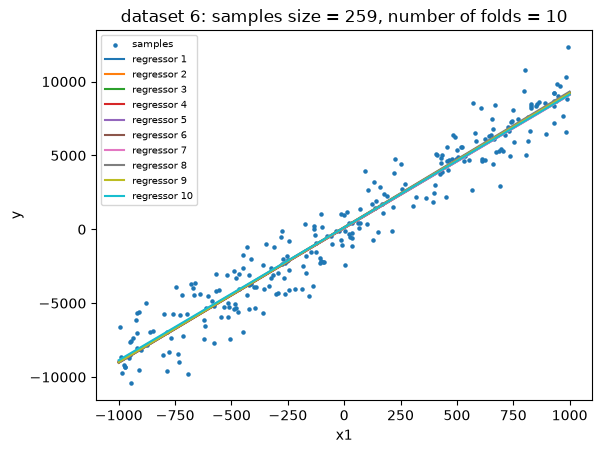


dataset 7: y = 6.71 + (0.72)·tanh(x1) + (-0.17)·abs(x2) + (-5.81)·sqrt(x3) + (6.30)·tanh(x4) + (-5.43)·x5^5 + (4.28)·sin(x6) + (8.69)·x7^4
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1 750571623151860.6250 630650174818658.3750      1109.0314     0.5290   y = 40371877448376.1328 + (145143838337.9583)·x1 + (54980335839.5584)·x2 + (24674046407.7842)·x3 + (215046336345.4778)·x4 + (-2053148120465.1414)·x5 + (42127950369.5804)·x6 + (164442486061.7214)·x7
       2 1093863252066702.0000 814083649885135.6250       116.0674     0.6781   y = 64860356332825.6719 + (214396832671.4991)·x1 + (34743827885.6713)·x2 + (21360947426.4228)·x3 + (181544994936.2774)·x4 + (-1970125392141.4041)·x5 + (8166498273.8990)·x6 + (72056090699.5894)·x7
       3 778236170728204.5000 641758735145159.1250     14750.2741     0.6283   y = 54164697345344.7656 + (156941565904.0677)·x1 + (63902974329.1437)·x2 + (33886143485.4641)·x3 + (197679503943.2326)·x4 + (-2085999975581.0

In [10]:
k = 10

cross_validation_results = []

for dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y) in datasets:
    X_with_bias = np.hstack((np.ones((samples_size, 1)), X))
    folds = np.array_split(np.arange(samples_size), k)

    fold_results = []

    for f in range(k):
        test_indices = folds[f]
        train_indices = np.concatenate([folds[m] for m in range(k) if m != f])

        X_train, y_train = X_with_bias[train_indices], y[train_indices]
        X_test, y_test = X_with_bias[test_indices], y[test_indices]

        # training the linear regression model using the normal equation
        w = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

        # training done, now we get to testing
        y_predicted = X_test @ w
        rmse = np.sqrt(np.mean((y_predicted - y_test) ** 2))
        mae = np.mean(np.abs(y_test - y_predicted))
        mape = np.mean(np.abs((y_test - y_predicted) / y_test)) * 100
        r2 = 1 - np.sum((y_test - y_predicted) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)

        fold_results.append((w, rmse, mae, mape, r2))

    average_rmse = np.mean([rmse for w, rmse, mae, mape, r2 in fold_results])
    average_mae = np.mean([mae for w, rmse, mae, mape, r2 in fold_results])
    average_mape = np.mean([mape for w, rmse, mae, mape, r2 in fold_results])
    average_r2 = np.mean([r2 for w, rmse, mae, mape, r2 in fold_results])

    cross_validation_results.append((fold_results, average_rmse, average_mae, average_mape, average_r2))

for i in range(len(datasets)):
    dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y) = datasets[i]
    fold_results, average_rmse, average_mae, average_mape, average_r2 = cross_validation_results[i]

    equations = []
    for w, rmse, mae, mape, r2 in fold_results:
        equation = f"y = {w[0]:.4f}"
        for j in range(dimension):
            equation += f" + ({w[j + 1]:.4f})·x{j + 1}"
        equations.append(equation)

    print(f"dataset {i + 1}: {formula}")
    print(f"{'fold':>8} {'RMSE':>14} {'MAE':>14} {'MAPE (%)':>14} {'R²':>10}   estimated regressor")
    for f, (w, rmse, mae, mape, r2) in enumerate(fold_results):
        print(f"{f + 1:>8} {rmse:>14.4f} {mae:>14.4f} {mape:>14.4f} {r2:>10.4f}   {equations[f]}")
    print(f"{'average':>8} {average_rmse:>14.4f} {average_mae:>14.4f} {average_mape:>14.4f} {average_r2:>10.4f}")

    if dimension == 1:
        plt.figure()
        plt.scatter(X[:, 0], y, s=5, label="samples")
        x_line = np.array([-1000, 1000])
        for f, (w, rmse, mae, mape, r2) in enumerate(fold_results):
            plt.plot(x_line, w[0] + w[1] * x_line, label=f"regressor {f + 1}")
        plt.title(f"dataset {i + 1}: samples size = {samples_size}, number of folds = {k}")
        plt.xlabel("x1")
        plt.ylabel("y")
        plt.legend(fontsize=7)
        plt.show()

    print()